# Electricity Forecasting Application
## 01 — Exploratory Data Analysis (EDA)

### Objective

Explore the UCI Electricity Load Diagrams 2011–2014 dataset, covering 370 electricity meters, to analyze consumption patterns, identify similarities, and discover meaningful clusters.

The findings will support the development and comparison of three forecasting approaches: a general-purpose LSTM, cluster-specific LSTM models, and a jointly trained Mixture of Experts (MoE).

### Dataset

- **Source:** UCI Machine Learning Repository
- **Meters:** 370 electricity consumers
- **Measurement frequency:** 15-minute intervals
- **Input window:** 96 observations (24 hours)
- **Forecasting horizon:** Next observation (15 minutes ahead)
- **Prediction target:** One electricity meter at a time

### Analysis Steps

1. **Data Loading & Inspection:** Load and inspect the 370 electricity meters.
2. **Data Cleaning & Validation:** Identify and handle inactive periods, missing values, and zeros.
3. **Correlation Analysis:** Analyze similarities between electricity consumption patterns using Pearson correlation.
4. **Cluster Discovery & Evaluation:** Identify and evaluate groups of meters with similar temporal behaviors.
5. **Exploratory Conclusions:** Summarize the findings and define preprocessing requirements for model training.

**Note:** Initial data cleaning and exploratory analysis are performed in this notebook. Further preprocessing for model training, including normalization, chronological data splitting, and sequence generation, will be performed in separate notebooks.

### 1. Data Loading & Inspection

This step loads the electricity consumption data from all **370 meters** into a Pandas DataFrame.

The objective is to verify the dataset structure (**140,256 observations and 371 columns**) and prepare the data for cleaning, correlation analysis, and clustering.

In [1]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/LD2011_2014.txt")
# Chargement de tous les compteurs électriques
df_all = pd.read_csv(
    file_path,
    sep=";",
    decimal=",",
    parse_dates=[0]
)

# Vérification des dimensions et des premières lignes
print("Dimensions :", df_all.shape)
display(df_all.head())

Dimensions : (140256, 371)


,Unnamed: 0,MT_001,MT_002,MT_003,MT_004,MT_005,MT_006,MT_007,MT_008,MT_009,...,MT_361,MT_362,MT_363,MT_364,MT_365,MT_366,MT_367,MT_368,MT_369,MT_370
0,2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2011-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2011-01-01 01:15:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 2. Data Cleaning — Handling Initial and Trailing Zeros

This step identifies and replaces inactive periods (leading and trailing zeros) with `NaN` for all 370 electricity meters, while preserving valid zeros within active periods.

The goal is to improve data quality and ensure reliable correlation analysis and clustering without losing temporal alignment between meters.

In [2]:
import numpy as np

# Copie des données pour préserver le DataFrame original
df_clean = df_all.copy()

# Sélection des 370 colonnes de compteurs
meter_cols = [col for col in df_clean.columns if col.startswith("MT_")]

# Parcours de chaque compteur
for col in meter_cols:
    serie = df_clean[col]

    # Identifier les positions où la consommation est non nulle
    positions = np.flatnonzero(serie.notna() & (serie != 0))

    # Ignorer les compteurs entièrement nuls
    if len(positions) == 0:
        df_clean[col] = np.nan
        continue

    # Première et dernière observations non nulles
    debut = positions[0]
    fin = positions[-1]

    # Exclure uniquement les zéros en début et fin de série
    df_clean.loc[df_clean.index[:debut], col] = np.nan
    df_clean.loc[df_clean.index[fin + 1:], col] = np.nan

# Vérification du nettoyage
print("Dimensions :", df_clean.shape)
print("Valeurs NaN après nettoyage :",
      df_clean[meter_cols].isna().sum().sum())

Dimensions : (140256, 371)
Valeurs NaN après nettoyage : 10039214


### 2.1. Data Cleaning Validation

This step verifies the cleaning results on five selected meters (`MT_001`, `MT_025`, `MT_100`, `MT_200`, `MT_370`).

**Meter Selection:** The five meters were manually selected from different positions in the dataset to check the cleaning process across multiple time series. This is not a random or statistically representative selection.

**Objective:** Confirm that inactive periods were replaced with `NaN` while preserving valid zeros within active periods, ensuring data quality for correlation analysis and clustering.


In [3]:
# Compteurs sélectionnés pour vérifier le nettoyage
compteurs = ["MT_001", "MT_025", "MT_100", "MT_200", "MT_370"]

resultats = []

for col in compteurs:
    serie = df_clean[col]

    # Identifier les premières et dernières observations valides
    debut = serie.first_valid_index()
    fin = serie.last_valid_index()

    # Rassembler les résultats du contrôle
    resultats.append({
        "Compteur": col,
        "Première position": debut,
        "Dernière position": fin,
        "NaN": serie.isna().sum(),
        "Zéros conservés": (serie == 0).sum()
    })

# Afficher le tableau récapitulatif
display(pd.DataFrame(resultats))

,Compteur,Première position,Dernière position,NaN,Zéros conservés
0,MT_001,35040,140255,35040,5703
1,MT_025,35040,140255,35040,12
2,MT_100,35040,140255,35040,4
3,MT_200,0,140255,0,16
4,MT_370,70176,140255,70176,153


### 3. Correlation Analysis

This step calculates the **Pearson correlation coefficients** between all 370 electricity meters using cleaned data.

**Objectives:**
- Measure the similarity between electricity consumption patterns.
- Identify strongly correlated meters.
- Count overlapping valid observations to assess correlation reliability.
- Visualize the correlation matrix using a **heatmap**.

**Expected Analysis Outputs:**
1. **Correlation Matrix (370 × 370):** Pearson coefficients ranging from −1 to +1, showing relationships between meters.
2. **Overlap Matrix (370 × 370):** Number of valid observations shared by each pair of meters.
3. **Correlation Heatmap:** Visual representation highlighting strongly correlated groups and differences in consumption behavior.
4. **Potential Cluster Identification:** Identification of candidate groups of meters with similar temporal patterns, without determining the final number of clusters.

**Purpose:** These results provide the foundation for clustering electricity meters and training specialized LSTM models for each group.

In [4]:
# Calcul des corrélations entre les 370 compteurs
corr_matrix = df_clean[meter_cols].corr(method="pearson")

# Nombre d'observations communes valides entre chaque paire
valid = df_clean[meter_cols].notna().astype("int32")
overlap_matrix = valid.T @ valid

# Vérification des dimensions
print("Matrice de corrélation :", corr_matrix.shape)
print("Matrice des observations communes :", overlap_matrix.shape)

# Aperçu des corrélations entre les cinq premiers compteurs
display(corr_matrix.iloc[:5, :5].round(3))

Matrice de corrélation : (370, 370)
Matrice des observations communes : (370, 370)


,MT_001,MT_002,MT_003,MT_004,MT_005
MT_001,1.000,0.111,0.083,-0.029,-0.039
MT_002,0.111,1.000,-0.057,0.186,0.003
MT_003,0.083,-0.057,1.000,0.043,0.130
MT_004,-0.029,0.186,0.043,1.000,0.748
MT_005,-0.039,0.003,0.130,0.748,1.000


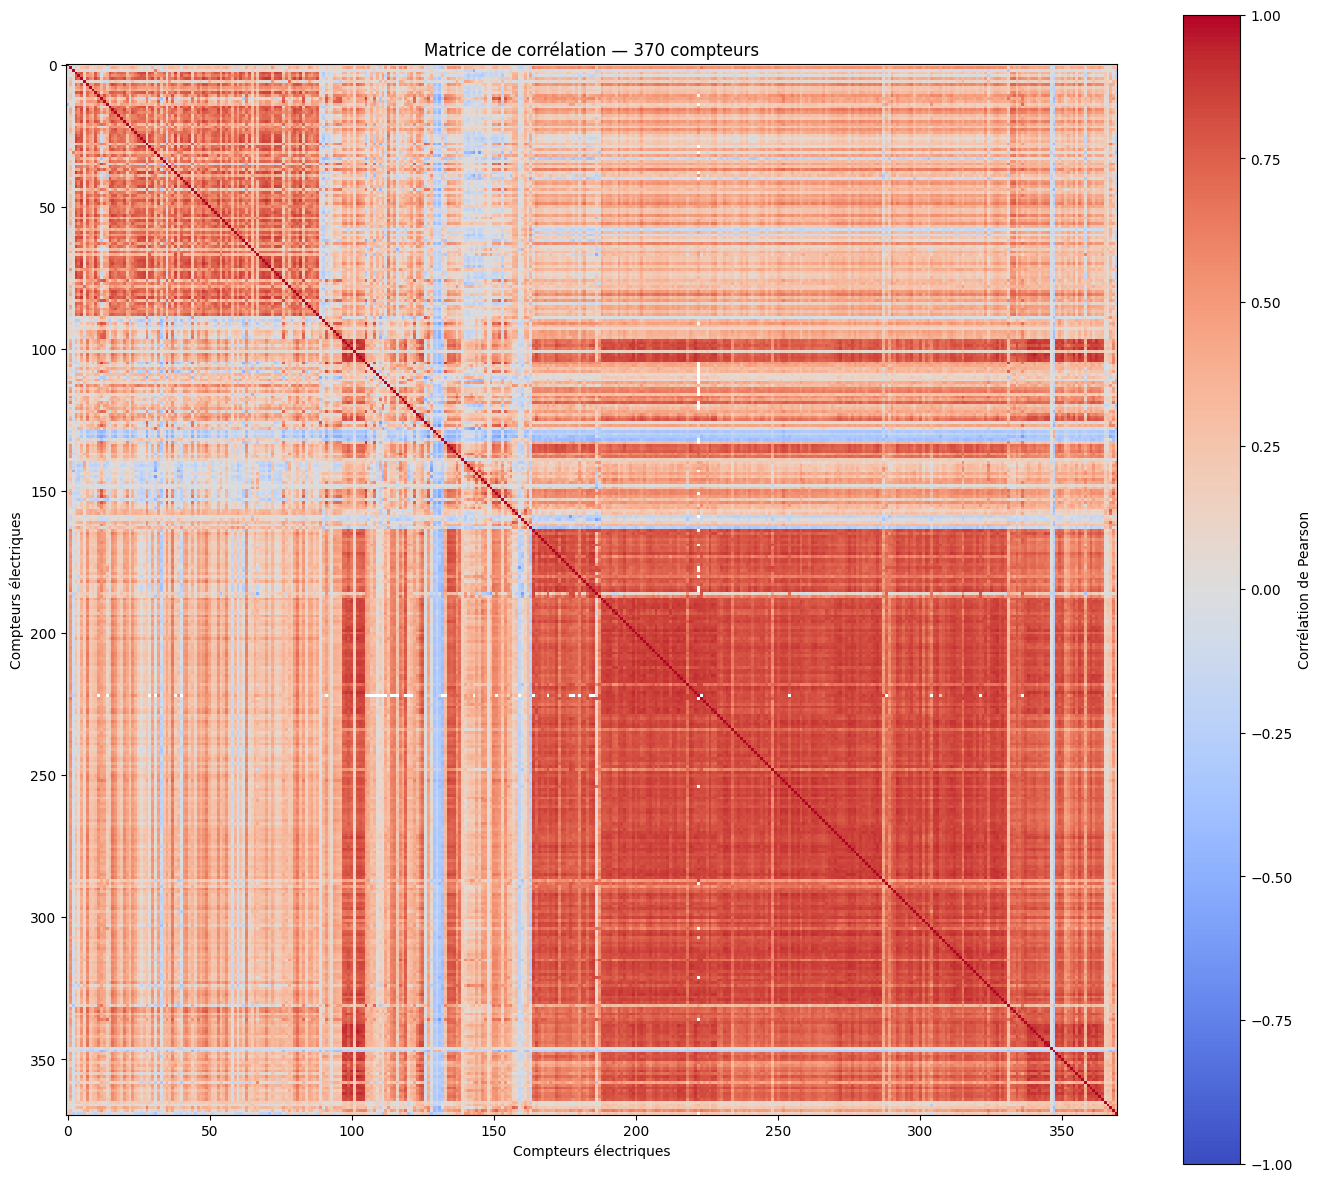

In [5]:
import matplotlib.pyplot as plt

# Création de la figure
plt.figure(figsize=(14, 12))

# Affichage de la matrice de corrélation
plt.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)

# Échelle des coefficients de corrélation
plt.colorbar(label="Corrélation de Pearson")

# Titres et axes
plt.title("Matrice de corrélation — 370 compteurs")
plt.xlabel("Compteurs électriques")
plt.ylabel("Compteurs électriques")

plt.tight_layout()
plt.show()

### 4. Cluster Discovery & Evaluation

**Objective:** Identify groups of electricity meters with similar temporal consumption patterns, independently of their consumption magnitude.

**Methodology:**
1. Assess correlation matrix reliability.
2. Apply hierarchical clustering based on correlation distance.
3. Visualize clusters using a dendrogram.
4. Evaluate cluster quality and determine an appropriate number of clusters.
5. Compare alternative clustering methods if necessary.

**Expected Output:** Meaningful groups of meters with similar consumption behaviors, providing a foundation for training cluster-specific LSTM forecasting models.

#### 4.2. Correlation Reliability Assessment

**Objective:** Evaluate the reliability of correlations between the 370 electricity meters by examining the number of valid overlapping observations.

**Method:**
- Analyze all **68,265 unique meter pairs**.
- Calculate the minimum, median, and maximum number of shared observations.
- Apply a preliminary threshold of **10,000 observations**, equivalent to approximately **104 days** (96 observations per day at 15-minute intervals: 10,000 ÷ 96 ≈ 104.17).
- Identify the number and percentage of pairs below this threshold.

**Expected Outputs:** Overlap statistics and the percentage of meter pairs with insufficient shared observations.

**Purpose:** Determine whether the correlation matrix provides a sufficiently reliable basis for clustering or whether some meter pairs require additional analysis.

**Note:** The 10,000-observation threshold is provisional. It represents approximately 104 days of measurements, but these observations are not necessarily consecutive. Sufficient overlap does not guarantee stable correlations.

In [6]:
import numpy as np

# Extraire les paires de compteurs sans doublons
i, j = np.triu_indices(len(meter_cols), k=1)

# Nombre d'observations communes par paire
overlaps = overlap_matrix.to_numpy()[i, j]

# Seuil minimal proposé
min_overlap = 10000

# Vérification de la couverture temporelle
print("Nombre de paires :", len(overlaps))
print("Minimum :", overlaps.min())
print("Médiane :", np.median(overlaps))
print("Maximum :", overlaps.max())

# Identifier les paires sous le seuil
insufficient = (overlaps < min_overlap).sum()

print("Paires insuffisantes :", insufficient)
print("Pourcentage :", round(insufficient / len(overlaps) * 100, 2), "%")

Nombre de paires : 68265
Minimum : 0
Médiane : 105216.0
Maximum : 140256
Paires insuffisantes : 47
Pourcentage : 0.07 %


#### 4.2.1. Results Analysis & Decision

**Results:**
- **Total meter pairs:** 68,265
- **Minimum overlap:** 0 observations
- **Median overlap:** 105,216 observations
- **Maximum overlap:** 140,256 observations
- **Insufficient overlap:** 47 pairs (0.07%)

**Analysis:**

Approximately **99.93% of meter pairs** meet the minimum threshold of 10,000 shared observations. The median overlap of 105,216 observations (approximately 1,096 days) indicates substantial temporal coverage for most comparisons.

However, 47 pairs fall below the threshold, including potentially non-overlapping meters.

**Decision:**

The correlation matrix provides a suitable starting point for exploratory clustering. However, the 47 insufficiently overlapping pairs must be identified and handled before constructing the clustering distance matrix. Any undefined correlations must also be checked.

**Next Step — 4.3. Hierarchical Clustering:**

Identify unreliable meter pairs, construct a valid correlation-based distance matrix, and apply hierarchical clustering to discover groups of meters with similar consumption patterns.

In [7]:
# Identifier les paires ayant moins de 10 000 observations communes
unreliable_pairs = []

for i, j in zip(*np.triu_indices(len(meter_cols), k=1)):
    meter_a = meter_cols[i]
    meter_b = meter_cols[j]
    overlap = overlap_matrix.loc[meter_a, meter_b]

    if overlap < min_overlap:
        unreliable_pairs.append({
            "Meter A": meter_a,
            "Meter B": meter_b,
            "Overlap": overlap,
            "Correlation": corr_matrix.loc[meter_a, meter_b]
        })

# Afficher les paires problématiques
df_unreliable = pd.DataFrame(unreliable_pairs)

display(df_unreliable)

,Meter A,Meter B,Overlap,Correlation
0,MT_012,MT_223,0,NaN
1,MT_015,MT_223,0,NaN
2,MT_030,MT_223,0,NaN
3,MT_032,MT_223,0,NaN
4,MT_033,MT_223,6876,0.614361
5,MT_039,MT_223,0,NaN
6,MT_041,MT_223,0,NaN
7,MT_092,MT_223,0,NaN
8,MT_106,MT_223,0,NaN
9,MT_107,MT_223,0,NaN


#### 4.3.1. Unreliable Pair Analysis

**Findings:**
- All 47 insufficient-overlap pairs involve meter `MT_223`.
- 40 pairs have no shared valid observations, resulting in undefined Pearson correlations.
- The remaining 7 pairs have between 3,042 and 8,950 shared observations, below the 10,000-observation threshold.
- Among these pairs, `MT_167` shows the strongest positive correlation with `MT_223` (**r = 0.790**, based on 8,950 shared observations).

**Interpretation:**

The insufficient overlap is concentrated around a single meter (`MT_223`). Its relatively strong correlation with `MT_167` suggests potentially similar consumption patterns, although the available overlap remains below our reliability threshold.

**Decision — Cluster Assignment Strategy:**

1. Perform hierarchical clustering on the **369 remaining meters**, excluding `MT_223`.
2. Identify the cluster containing `MT_167`.
3. Provisionally assign `MT_223` to the same cluster as `MT_167`, based on their observed correlation.
4. Retain all 370 meters in the overall study.

This assignment is heuristic and will require validation. For predictive modeling, clustering and assignment rules must be established using training data only to avoid data leakage.

**Next Step — 4.4. Hierarchical Clustering:**

Construct a correlation-based distance matrix for the 369 meters, apply hierarchical clustering, and visualize their relationships using a dendrogram.

#### 4.4. Hierarchical Clustering — Distance Matrix Construction

**Objective:** Prepare a distance matrix to group electricity meters based on similarities in their consumption patterns.

**Method:**
1. Temporarily exclude `MT_223`, leaving 369 meters for hierarchical clustering.
2. Extract the corresponding Pearson correlation matrix.
3. Convert correlation coefficients into distances using:

   \[
   d(A,B) = 1 - r(A,B)
   \]

   where \(r(A,B)\) is the Pearson correlation between meters A and B.

**Interpretation:**
- Correlation close to +1 → Distance close to 0 → Similar consumption patterns.
- Correlation close to 0 → Distance close to 1 → Weak linear relationship.
- Correlation close to −1 → Distance close to 2 → Opposite consumption patterns.

**Expected Outputs:**
- A 369 × 369 distance matrix.
- Verification that distances are within the range [0, 2].
- Verification that no missing values (`NaN`) remain.

**Next Step:** Use the validated distance matrix to perform hierarchical clustering and generate a dendrogram.

In [8]:
# Exclure temporairement MT_223 du clustering
cluster_meters = [m for m in meter_cols if m != "MT_223"]

# Extraire les corrélations des 369 compteurs
corr_clustering = corr_matrix.loc[cluster_meters, cluster_meters]

# Transformer les corrélations en distances
distance_matrix = 1 - corr_clustering

# Vérifier les dimensions et les valeurs manquantes
print("Dimensions :", distance_matrix.shape)
print("Distances manquantes :", distance_matrix.isna().sum().sum())
print("Distance minimale :", distance_matrix.min().min())
print("Distance maximale :", distance_matrix.max().max())

Dimensions : (369, 369)
Distances manquantes : 0
Distance minimale : 0.0
Distance maximale : 1.6627960155000276


**Results & Decision:**

The resulting distance matrix has dimensions of 369 × 369, contains no missing values, and has distances ranging from 0 to approximately 1.663.

These results confirm that the matrix is suitable for hierarchical clustering. Some meter pairs exhibit negative correlations, indicating potentially opposite consumption patterns.

Next Step : Apply hierarchical clustering to the 369 meters and visualize their relationships using a dendrogram to identify potential consumption groups.

#### 4.5. Hierarchical Clustering & Dendrogram

**Objective:** Apply hierarchical clustering to the 369 electricity meters to visualize similarities in their consumption patterns.

**Method:**
1. Convert the correlation-based distance matrix into condensed form.
2. Apply agglomerative hierarchical clustering using average linkage.
3. Visualize the resulting hierarchy with a dendrogram.

**Expected Output:** A dendrogram showing how electricity meters progressively merge into groups based on their consumption similarities.

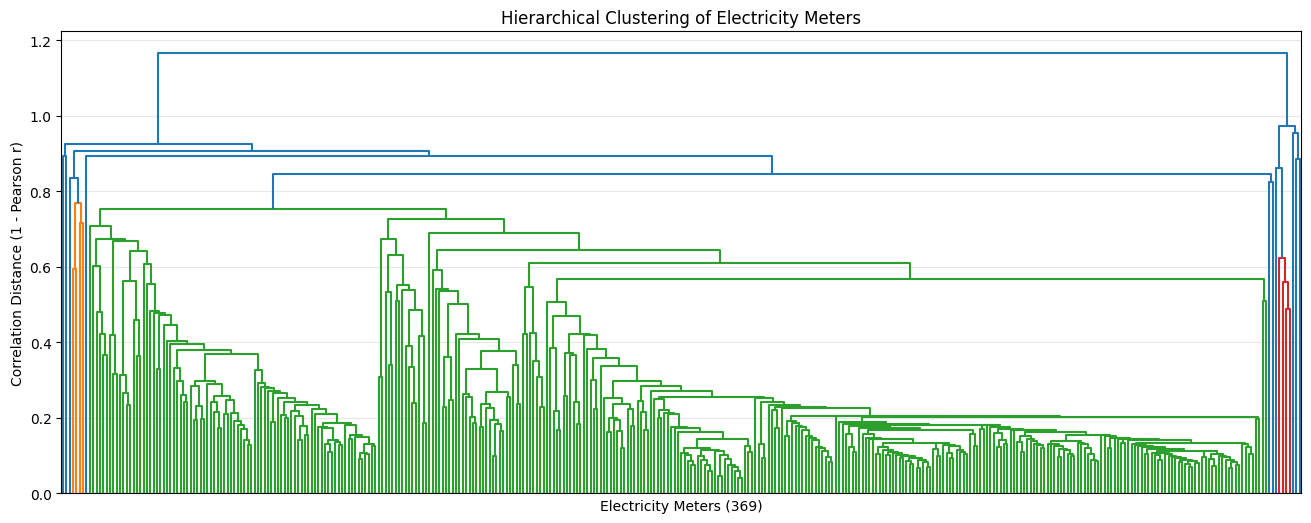

In [10]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt

# Convertir la matrice de distances au format condensé
condensed_distances = squareform(distance_matrix.to_numpy())

# Construire le clustering hiérarchique
Z = linkage(condensed_distances, method="average")

# Afficher le dendrogramme
plt.figure(figsize=(16, 6))

dendrogram(
    Z,
    no_labels=True
)

plt.title("Hierarchical Clustering of Electricity Meters")
plt.xlabel("Electricity Meters (369)")
plt.ylabel("Correlation Distance (1 - Pearson r)")
plt.grid(axis="y", alpha=0.3)
plt.show()

#### 4.6. Optimal Number of Clusters — Silhouette Analysis

**Objective:** Evaluate different numbers of clusters to identify an appropriate grouping of electricity meters.

**Method:**
1. Extract cluster assignments from the hierarchical clustering tree for different values of \(k\).
2. Calculate the Silhouette Score using the correlation-based distance matrix.
3. Compare the scores and cluster sizes to identify a suitable number of clusters.

**Expected Output:** A graph showing the Silhouette Score for each tested number of clusters.

**Decision Criterion:** Prefer well-separated clusters while avoiding excessively small groups, since each cluster may later require its own LSTM forecasting model.

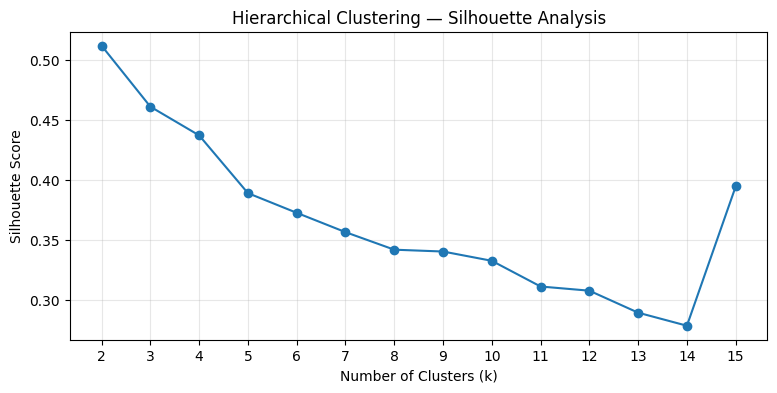

In [11]:
from scipy.cluster.hierarchy import cut_tree
from sklearn.metrics import silhouette_score

# Tester différents nombres de clusters
k_values = range(2, 16)
scores = []

for k in k_values:
    # Découper le dendrogramme en k clusters
    labels = cut_tree(Z, n_clusters=k).ravel()

    # Calculer le score avec nos distances de corrélation
    score = silhouette_score(
        distance_matrix.to_numpy(),
        labels,
        metric="precomputed"
    )

    scores.append(score)

# Visualiser les résultats
plt.figure(figsize=(9, 4))
plt.plot(list(k_values), scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical Clustering — Silhouette Analysis")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

#### 4.7. Cluster Size Distribution Analysis

**Objective:** Evaluate the distribution of electricity meters across clusters for k = 2, 3, and 4.

**Method:**
1. Extract cluster assignments from the hierarchical clustering tree.
2. Count the number of meters belonging to each cluster.
3. Compare cluster sizes to identify potentially unbalanced groupings.

**Expected Output:** A table showing the number of meters assigned to each cluster for different values of k.

**Decision Criterion:** Balance the Silhouette Score with cluster sizes to select a suitable clustering configuration for training specialized LSTM models.

In [12]:
# Comparer la taille des clusters pour k = 2, 3 et 4
for k in [2, 3, 4]:
    labels = cut_tree(Z, n_clusters=k).ravel()

    cluster_sizes = (
        pd.Series(labels + 1)
        .value_counts()
        .sort_index()
    )

    print(f"\nNumber of clusters: {k}")
    print(cluster_sizes.to_string())


Number of clusters: 2
1    361
2      8

Number of clusters: 3
1    361
2      3
3      5

Number of clusters: 4
1    361
2      1
3      5
4      2
